0        5
1        5
2        5
3        4
4        3
        ..
20635    2
20636    2
20637    2
20638    2
20639    2
Name: income_cat, Length: 20640, dtype: category
Categories (5, int64): [1 < 2 < 3 < 4 < 5]


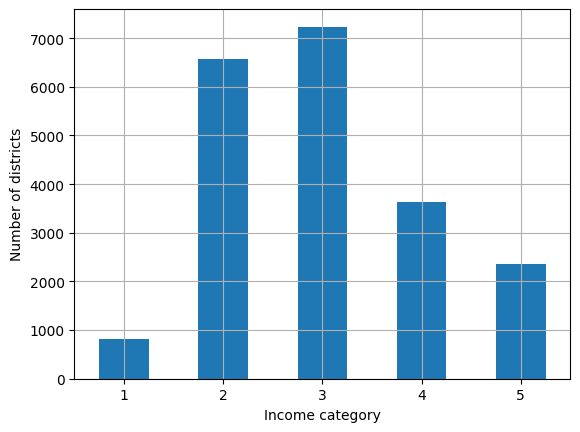

In [31]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

housing = pd.read_csv('/home/siyam/MyCodes/MachineLearning/Book/datasets/housing/housing.csv')

from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)


housing["income_cat"] = pd.cut(housing["median_income"],
                        bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                        labels=[1, 2, 3, 4, 5])

print(housing["income_cat"])

housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")

from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=.2, random_state=42)

In [2]:
from sklearn.model_selection import StratifiedShuffleSplit
splitter = StratifiedShuffleSplit(n_splits=10,test_size=0.2,random_state=42)

# strat_splits = []

# for trainidx, testidx in splitter.split(housing, housing['income_cat']):
#     strat_trn = housing.iloc[trainidx]
#     strat_tst = housing.iloc[testidx]
#     strat_splits.append([strat_trn, strat_tst])

# for i, (train,test) in enumerate(strat_splits):
#     print(f"Split {i+1}:")
#     print("Train: ", train.shape)
#     print("Test : ", test.shape)
#     print()

strat_train_set, strat_test_set = train_test_split(housing, test_size=0.2, 
                                                   stratify=housing['income_cat'], 
                                                   random_state=42)

print(strat_test_set)

for x in (strat_train_set, strat_test_set):
    x.drop('income_cat', axis=1, inplace=True)

print(strat_test_set)


       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
3905     -121.95     37.11                21.0       2387.0           357.0   
16821    -118.01     33.89                36.0       1589.0           265.0   
2900     -118.18     33.74                30.0       5915.0          1750.0   
7193     -122.48     37.74                52.0       2166.0           423.0   
13928    -122.39     37.78                 5.0       1405.0           515.0   
...          ...       ...                 ...          ...             ...   
12369    -124.16     40.79                46.0       3042.0           597.0   
8707     -119.01     35.39                29.0       1820.0           459.0   
16634    -123.01     38.67                33.0        914.0           147.0   
9779     -122.03     37.60                24.0       2077.0           383.0   
3455     -117.12     32.74                52.0       1969.0           389.0   

       population  households  median_income  media

<Axes: xlabel='longitude', ylabel='latitude'>

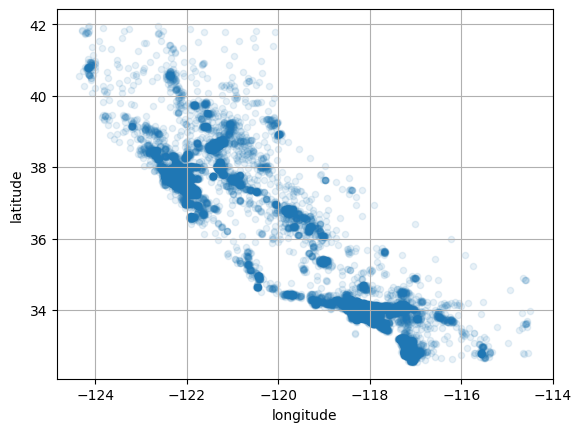

In [3]:
housing = strat_train_set.copy()

housing.plot(kind='scatter', x='longitude', y= 'latitude', grid= 'True', alpha=.1)

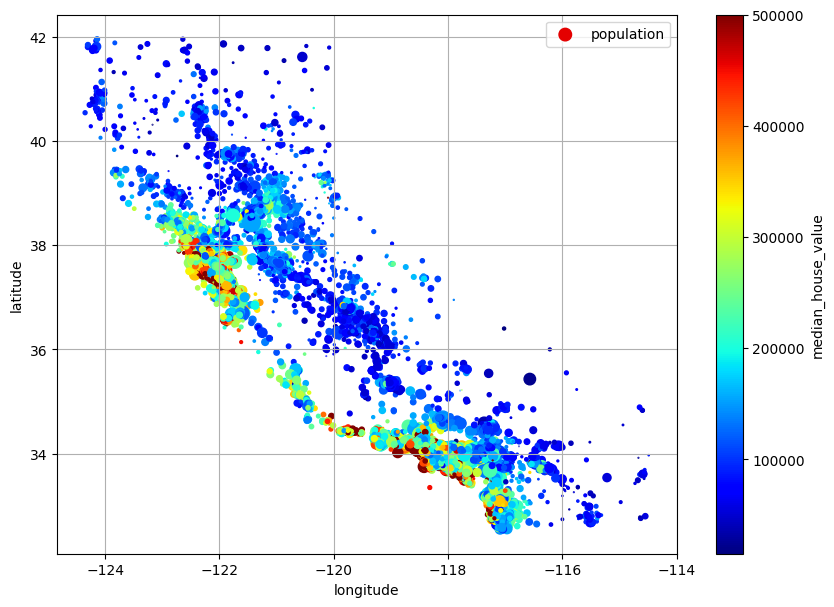

In [4]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    c="median_house_value",
    cmap="jet",
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)
plt.show()

In [5]:
correlation_matrix = housing.corr(numeric_only=True)
correlation_matrix["median_house_value"].sort_values(ascending=False)

print(housing.info())

<class 'pandas.DataFrame'>
Index: 16512 entries, 13096 to 19888
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16344 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   median_house_value  16512 non-null  float64
 9   ocean_proximity     16512 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.4 MB
None


array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='median_income', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='housing_median_age', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housing_median_age'>,
        <Axes: xlabel='median_income', ylabel='housing_median_age'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='median_income', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='median_income'>,
        <Axes: xlabel='housing_median_age', ylabel='median_income'>,
        <Axes: xlabel='total_rooms'

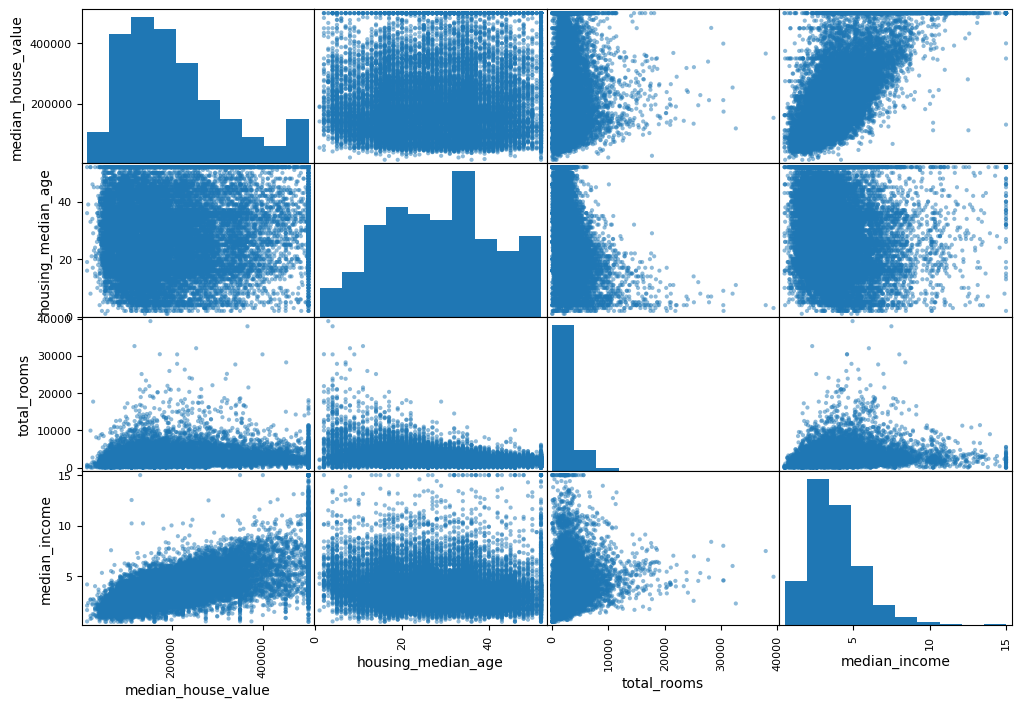

In [35]:
from pandas.plotting import scatter_matrix
attributes = ['median_house_value', 'housing_median_age', 'total_rooms', 'median_income']
scatter_matrix(housing[attributes], figsize=(12,8))

<Axes: xlabel='median_income', ylabel='median_house_value'>

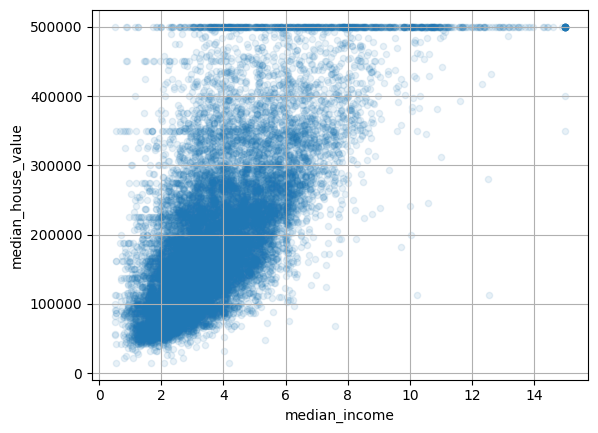

In [7]:
housing.plot(x='median_income',
             y='median_house_value',
             alpha=0.1,
             grid=True,
             kind='scatter')

In [8]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN


In [9]:
housing['rooms_per_house'] = housing['total_rooms'] / housing['households']
housing['bedrooms_ratio']  = housing['total_bedrooms'] / housing['total_rooms']
housing['people_per_house']= housing['population'] / housing['households']

In [10]:
corr_matrix = housing.corr(numeric_only=True)
print(corr_matrix)

                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924213           -0.102937     0.044558   
latitude            -0.924213  1.000000            0.005692    -0.036753   
housing_median_age  -0.102937  0.005692            1.000000    -0.361710   
total_rooms          0.044558 -0.036753           -0.361710     1.000000   
total_bedrooms       0.068210 -0.066391           -0.317978     0.930076   
population           0.104236 -0.115677           -0.301906     0.863967   
households           0.054261 -0.071604           -0.300075     0.916143   
median_income       -0.016542 -0.078137           -0.127043     0.197720   
median_house_value  -0.050859 -0.139584            0.102175     0.137455   
rooms_per_house     -0.027899  0.108037           -0.153900     0.128631   
bedrooms_ratio       0.087802 -0.108871            0.139119    -0.183273   
people_per_house     0.024587 -0.026457            0.012771    -0.037702   

           

In [11]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

## Removing whole row where there is missing value

In [ ]:
# median=housing["total_bedrooms"].median()
# housing['total_bedrooms'] = housing['total_bedrooms'].fillna(median)

# Imputer

In [46]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

housing_num = housing.select_dtypes(include=np.number)
# print(housing_num.info())
imputer.fit(housing_num)
print(imputer.statistics_)
print(housing_num.median().values)

X = imputer.transform(housing_num)

print('Number of NaN inside housing_num :\n',np.isnan(housing_num).sum())
print('Number of NaN inside X :',np.isnan(X).sum())

[-1.1849e+02  3.4260e+01  2.9000e+01  2.1270e+03  4.3500e+02  1.1660e+03
  4.0900e+02  3.5348e+00  1.7970e+05]
[-1.1849e+02  3.4260e+01  2.9000e+01  2.1270e+03  4.3500e+02  1.1660e+03
  4.0900e+02  3.5348e+00  1.7970e+05]
Number of NaN inside housing_num :
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
dtype: int64
Number of NaN inside X : 0


In [ ]:
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.experimental import enable_iterative_imputer
knn_imp = KNNImputer(n_neighbors=3)
it_imp  = IterativeImputer(max_iter=10, random_state=42)

